# 03 - Preprocesamiento de las imágenes
**Proyecto 2 - CGIAR Eyes on the Ground**

Este notebook corre en la laptop, donde está `train.zip`. Redimensiona las 26,068 fotos de entrenamiento, detecta archivos corruptos, guarda las dimensiones originales y empaqueta todo en un zip mucho más liviano (`images_224.zip`) para usarlo en Colab y en la app.

## 1. Decisiones

- **Tamaño 224×224:** es la entrada estándar de ResNet50 y EfficientNet-B0.
- **Redimensionado directo, sin recortar:** las señales de sequía pueden estar en cualquier parte de la foto (hojas, suelo, horizonte), y un recorte central podría perderlas. A cambio, las fotos con proporción distinta a 1:1 quedan algo deformadas.
- **Orientación EXIF:** varias fotos de celular vienen giradas según su metadato. Se corrige antes de redimensionar.
- **JPEG con calidad 95:** deja cada foto en unos pocos KB sin pérdida visible importante.
- **Solo train:** `test.zip` no tiene etiquetas, así que no se usa para entrenar ni evaluar.

In [1]:
import sys
from pathlib import Path
import zipfile
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.append(str(RAIZ))

from src.procesamiento_imagenes import redimensionar_desde_zip, TAMANO, CALIDAD

sns.set_theme(style="whitegrid")

RUTA_ZIP = RAIZ / "data" / "raw" / "train.zip"
DESTINO = RAIZ / "data" / "processed" / "images_224"
LIMITE = None   # poner un número (por ejemplo 300) para una prueba rápida

## 2. Qué fotos procesar

In [2]:
split = pd.read_csv(RAIZ / "data" / "splits" / "split.csv")
nombres = split["filename"].tolist()
if LIMITE:
    nombres = nombres[:LIMITE]

if not RUTA_ZIP.exists():
    raise FileNotFoundError(
        f"No se encontró {RUTA_ZIP}. Corré descargar_zip_si_no_existe('train') primero."
    )

stems = pd.Series([Path(n).stem for n in nombres])
assert stems.is_unique, "Hay nombres de foto que chocarían al guardarse como .jpg"
print(f"Fotos a procesar: {len(nombres)}")

Fotos a procesar: 26068


## 3. Redimensionar

Usa varios procesos y guarda un checkpoint por lote en `data/processed/images_224/_lotes/`. Si se interrumpe, se vuelve a correr la celda y continúa donde se quedó.

In [3]:
t0 = time.time()
meta = redimensionar_desde_zip(RUTA_ZIP, nombres, DESTINO, tamano=TAMANO, calidad=CALIDAD)
print(f"Tiempo: {(time.time() - t0) / 60:.1f} min")

Lotes totales: 53 | ya hechos: 37 | pendientes: 16
  5/16 lotes procesados
  10/16 lotes procesados
  15/16 lotes procesados
  16/16 lotes procesados
Tiempo: 0.2 min


## 4. Archivos corruptos o faltantes

In [4]:
print(f"OK: {meta['ok'].sum()} | con error: {(~meta['ok']).sum()}")
meta.loc[~meta["ok"], ["filename", "error"]]

OK: 26068 | con error: 0


,filename,error


In [5]:
# Qué clases de daño se ven afectadas por los errores (si los hubo)
con_error = meta[~meta["ok"]].merge(split[["filename", "damage", "split"]], on="filename")
con_error[["damage", "split"]].value_counts() if len(con_error) else "Sin errores"


'Sin errores'

In [6]:
# Se guarda la tabla con los datos de cada foto; los siguientes notebooks usan solo las que tienen ok = True
meta_completa = split.merge(meta, on="filename", how="right")
meta_completa.to_csv(RAIZ / "data" / "processed" / "imagenes_meta.csv", index=False)
meta_completa.head()

,ID,filename,growth_stage,season,damage,clase4,extent,grupo,split,archivo_224,ancho_orig,alto_orig,orientacion_exif,ok,error
0,ID_1S8OOWQYCB,L427F01330C01S03961Rp02052.jpg,S,SR2020,WD,Maleza,0,L427F01330,train,L427F01330C01S03961Rp02052.jpg,640,480,1,True,
1,ID_0MD959MIZ0,L1083F00930C39S12674Ip.jpg,V,SR2021,G,Bueno,0,L1083F00930,train,L1083F00930C39S12674Ip.jpg,320,240,1,True,
2,ID_JRJCI4Q11V,24_initial_1_1463_1463.JPG,V,LR2020,G,Bueno,0,N24,test,24_initial_1_1463_1463.jpg,640,480,1,True,
3,ID_DBO3ZGI1GM,L341F00167C01S00324Rp14178.jpg,M,SR2020,DR,Sequía,60,L341F00167,train,L341F00167C01S00324Rp14178.jpg,640,480,1,True,
4,ID_ORZLWTEUUS,L1084F02394C39S13931Ip.jpg,V,SR2021,G,Bueno,0,L1084F02394,train,L1084F02394C39S13931Ip.jpg,320,240,1,True,


## 5. Dimensiones originales

Sirve para la sección de limpieza del informe: muestra qué tan heterogéneas son las fotos y cuánta deformación introduce el redimensionado.

In [7]:
ok = meta[meta["ok"]].copy()
ok["relacion"] = ok["ancho_orig"] / ok["alto_orig"]
ok["megapixeles"] = ok["ancho_orig"] * ok["alto_orig"] / 1e6

print("Fotos horizontales (ancho > alto):", f"{(ok['relacion'] > 1).mean() * 100:.1f}%")
print("Fotos verticales (alto > ancho):  ", f"{(ok['relacion'] < 1).mean() * 100:.1f}%")
print("Cuadradas:                        ", f"{(ok['relacion'] == 1).mean() * 100:.1f}%")
print()
ok[["ancho_orig", "alto_orig", "relacion", "megapixeles"]].describe().round(2)

Fotos horizontales (ancho > alto): 98.2%
Fotos verticales (alto > ancho):   1.4%
Cuadradas:                         0.5%



,ancho_orig,alto_orig,relacion,megapixeles
count,26068.00,26068.00,26068.00,26068.00
mean,1037.75,724.60,1.37,1.59
std,1154.79,754.12,0.19,3.24
min,117.00,102.00,0.45,0.01
25%,320.00,260.00,1.33,0.08
50%,640.00,480.00,1.33,0.31
75%,640.00,480.00,1.33,0.31
max,4608.00,4160.00,2.22,15.93


In [8]:
print("Resoluciones más comunes:")
(ok.assign(res=ok["ancho_orig"].astype(int).astype(str) + "x" + ok["alto_orig"].astype(int).astype(str))
   ["res"].value_counts().head(8))

Resoluciones más comunes:


res
640x480      15247
320x240       5983
3264x2448     1388
3952x1872     1142
4160x3120      590
2592x1944      423
153x204        279
4128x1952      111
Name: count, dtype: int64

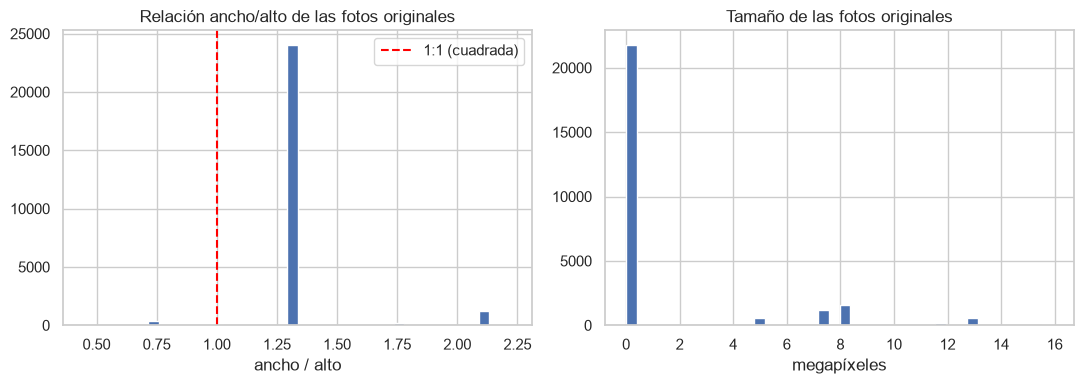

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(ok["relacion"].clip(0, 3), bins=40)
axes[0].axvline(1, color="red", linestyle="--", label="1:1 (cuadrada)")
axes[0].set_title("Relación ancho/alto de las fotos originales")
axes[0].set_xlabel("ancho / alto")
axes[0].legend()

axes[1].hist(ok["megapixeles"], bins=40)
axes[1].set_title("Tamaño de las fotos originales")
axes[1].set_xlabel("megapíxeles")

fig.tight_layout()
(RAIZ / "figuras").mkdir(exist_ok=True)
fig.savefig(RAIZ / "figuras" / "dimensiones_originales.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Verificación de las salidas

In [10]:
archivos = sorted(p for p in DESTINO.glob("*.jpg"))
print("Archivos .jpg generados:", len(archivos), "| fotos ok:", int(meta["ok"].sum()))

rng = np.random.default_rng(0)
muestra = rng.choice(len(archivos), size=min(20, len(archivos)), replace=False)
formas = {np.asarray(Image.open(archivos[i])).shape for i in muestra}
print("Formas de una muestra al azar:", formas)
assert formas == {(TAMANO, TAMANO, 3)}

Archivos .jpg generados: 26068 | fotos ok: 26068
Formas de una muestra al azar: {(224, 224, 3)}


## 7. Empaquetar para Drive

In [11]:
ruta_zip_salida = RAIZ / "data" / "processed" / "images_224.zip"
nombres_ok = meta.loc[meta["ok"], "archivo_224"].tolist()

# ZIP_STORED: los JPEG ya están comprimidos, volver a comprimirlos solo tarda más
with zipfile.ZipFile(ruta_zip_salida, "w", compression=zipfile.ZIP_STORED) as zf:
    for nombre in nombres_ok:
        zf.write(DESTINO / nombre, arcname=nombre)

print(f"{ruta_zip_salida.name}: {len(nombres_ok)} fotos, {ruta_zip_salida.stat().st_size / 1e6:.0f} MB")

images_224.zip: 26068 fotos, 801 MB


## Siguiente paso

1. Subir `images_224.zip` e `imagenes_meta.csv` a Drive (una sola vez).
2. En el notebook 04 (Colab) copiar el zip al disco local de Colab, descomprimirlo y extraer los embeddings.